In [1]:
import RocketSim
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import direct, Bounds

## Halo parameter flight sim

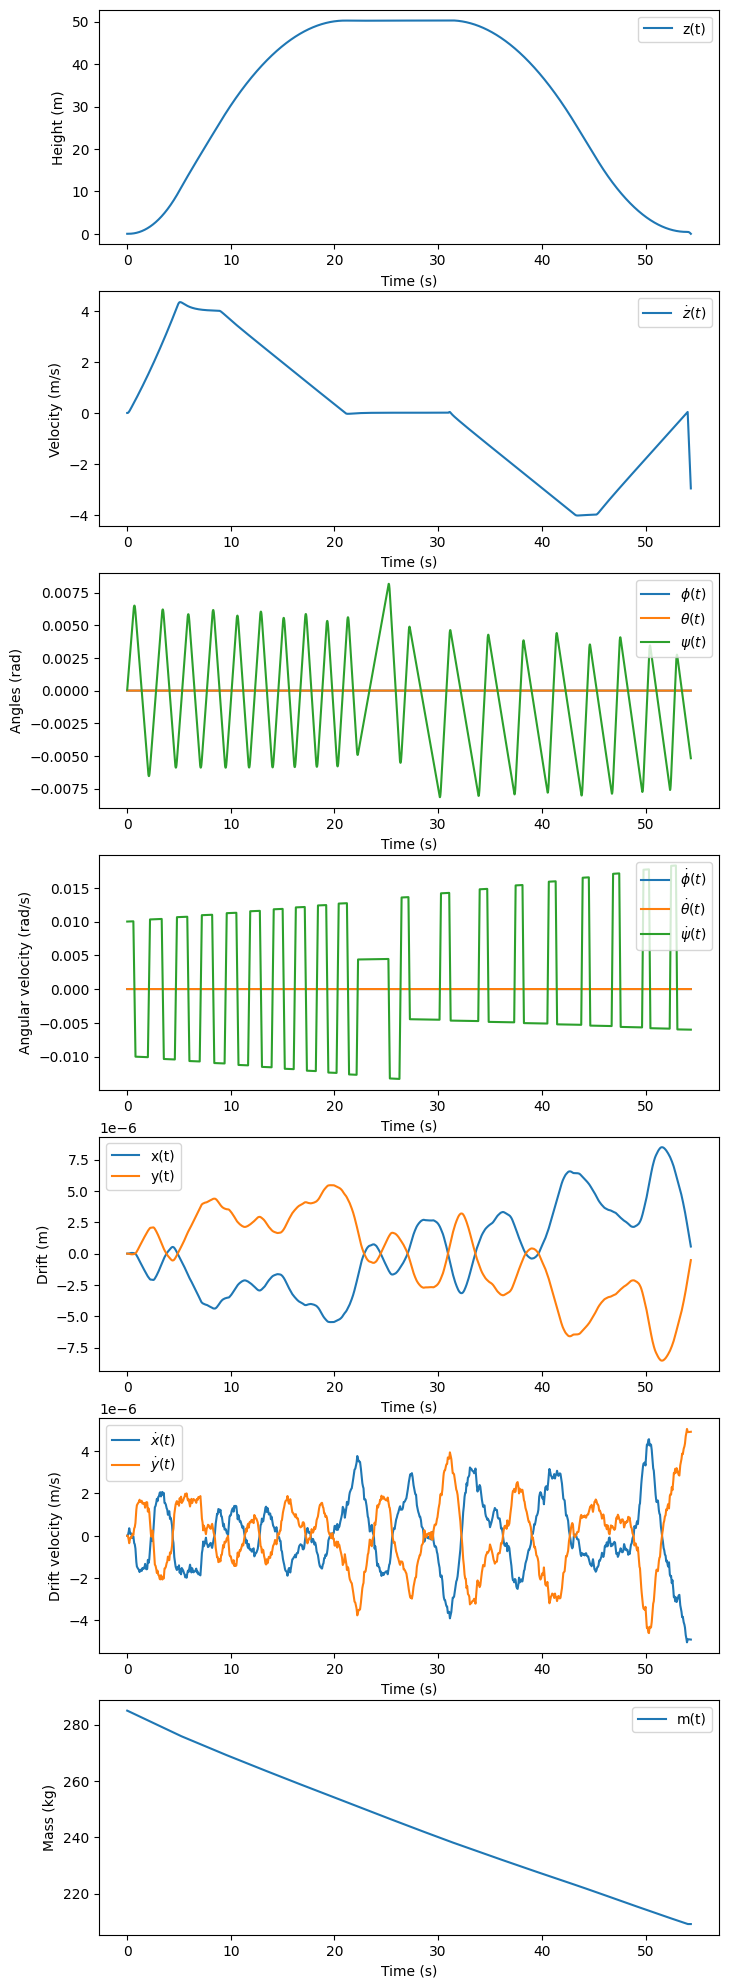

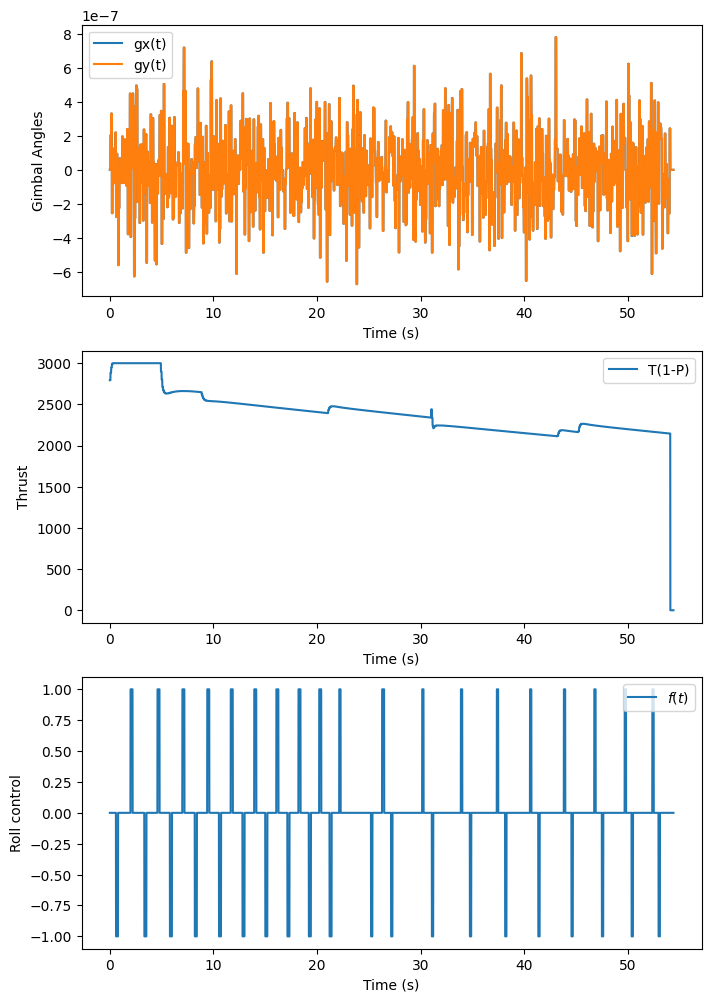

In [2]:
sim = RocketSim.RocketSim()
controls = RocketSim.Controls(Q = np.diag([0.1, 350.0, 0.1, 320.0, 20.0, 50.0]),
                              R = np.diag([2000.0, 1536.0]))

sim.clear_cache()
sim.with_control_algo(controls.LQR_control_algo).solve(State0 = [0,0,0,
                                                                    0,0,0,
                                                                    0,0,0,
                                                                    0,0,0.01, 285])
sim.plot_cache(interval=(0,65))

## Halo Jr parameter flight sim

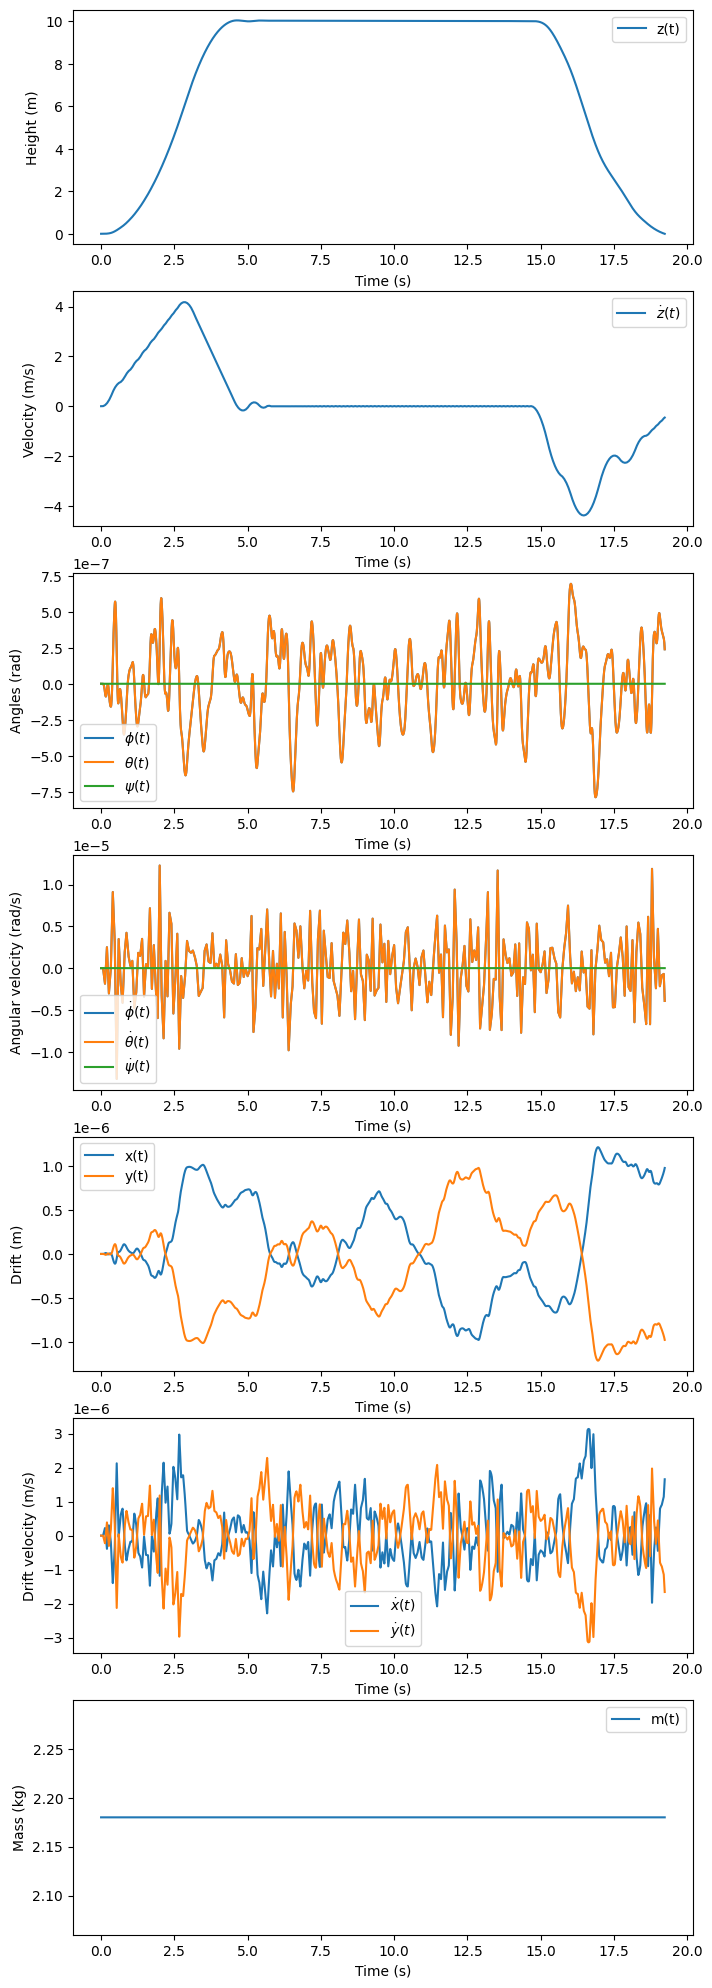

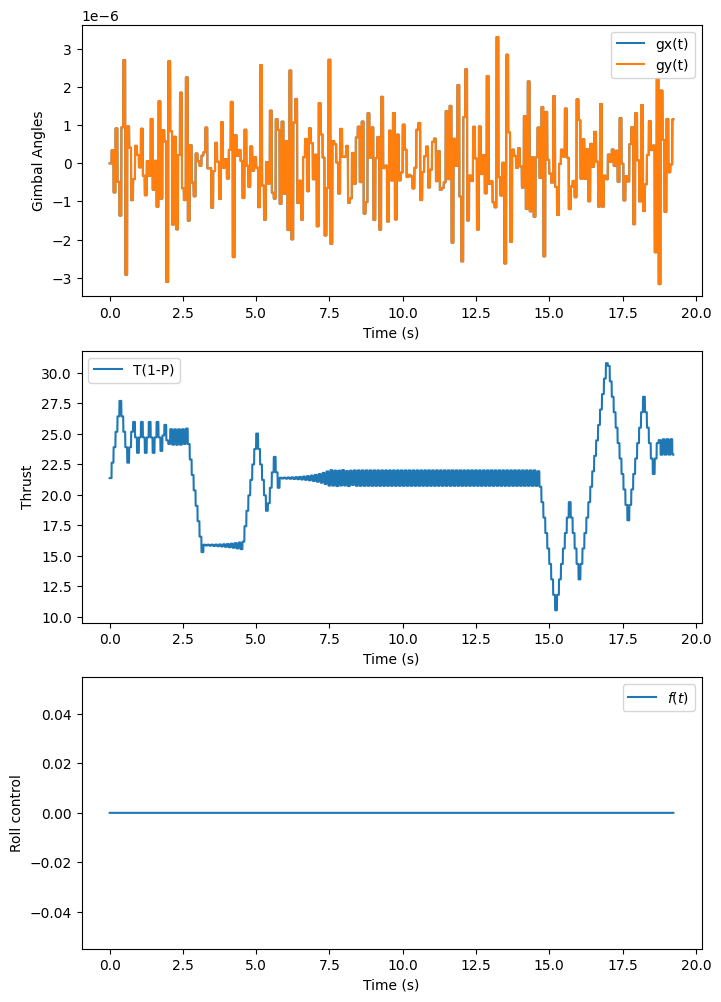

In [2]:
sim = RocketSim.RocketSim(T = 38,                  
                        P_max = 0.9,               
                        m0 = 2.18,                  
                        m_dot = 0,                                   
                        dNoz = 0.32,                
                        t_final = 20,                               
                        l = 0.7,                   
                        r = 0.05,                   
                        Tau0 = 0.15,
                        Cd0 = 0.8,
                        Cl0 = 6.28,
                        S0 = 0.0078,
                        dCoP = -0.03,
                        wind_speed = 0.0,
                        wind_direction = 0.0,
                        gust_variance = 0.0)
controls = RocketSim.Controls(H = 10.0,   
                            V = 4.0,    
                            Ti = 4.60,  
                            Th = 10.0, 
                            Tf = 19.6,
                            Z = 0.2 * (38/2.18 - 9.8),
                            Q = np.diag([4,53,4,5000,131,8.2]),
                            R = np.diag([200,1500]),
                            control_frequency = 15,
                            rocket=sim)
sim.clear_cache()
sim.with_control_algo(controls.LQR_control_algo).solve(State0 = [0,0,0,
                                                                    0,0,0,
                                                                    0,0,0,
                                                                    0,0,0, 2.18])
sim.plot_cache(interval=(0,65))

## Optimizing LQR parameters
Cost is the integral of the square of the difference between the true height and desired height: $\text{Cost} = \int_{0}^{t_f} \left( z(t)-z_{ref}(t) \right)^2 dt$

DIRECT optimization is used to find the global minimum within the bounds over the Q and R matrix diagonals

In [ ]:
def Cost(Qx,Qz,Qdx,Qdz,Qtheta,Qdtheta,Rgamma,RP):
    sim = RocketSim.RocketSim(T = 38,                  
                            P_max = 0.9,               
                            m0 = 2.18,                  
                            m_dot = 0,                                   
                            dNoz = 0.32,                
                            t_final = 20,                               
                            l = 0.7,                   
                            r = 0.05,                   
                            Tau0 = 0.15,
                            Cd0 = 0.8,
                            Cl0 = 6.28,
                            S0 = 0.0078,
                            dCoP = -0.03,
                            wind_speed = 0.0,
                            wind_direction = 0.0,
                            gust_variance = 0.0)
    controls = RocketSim.Controls(H = 10.0,   
                                V = 4.0,    
                                Ti = 4.60,  
                                Th = 10.0, 
                                Tf = 19.6,
                                Z = 0.2 * (38/2.18 - 9.8),
                                Q = np.diag([Qx,Qz,Qdx,Qdz,Qtheta,Qdtheta]),
                                R = np.diag([Rgamma,RP]),
                                control_frequency = 15,
                                rocket=sim)
    sim.clear_cache()
    sim.with_control_algo(controls.LQR_control_algo).solve(State0 = [0,0,0,
                                                                        0,0,0,
                                                                        0,0,0,
                                                                        0,0,0, 2.18])

    timestamps = sim.timestamps_cache[-1]
    height = sim.states_cache[-1][2]
    ref = [controls.z_ref(t) for t in timestamps]
    status = sim.status_cache[-1]

    if status == 0:
        Cost = np.sum([((height-ref) ** 2)[i] * (timestamps[i+1]-timestamps[i]) for i in range(len(timestamps)-1)])
    elif status == 2 and sim.t_final-timestamps[-1]<1:
        Cost = np.sum([((height-ref) ** 2)[i] * (timestamps[i+1]-timestamps[i]) for i in range(len(timestamps)-1)])
    else:
        Cost = 1e10

    return Cost

def cost(x):
    return Cost(*x)

bounds = Bounds([0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01], [10, 5000, 10, 100000, 1000, 500, 1500, 30000])
result = direct(cost, bounds)

best_x = result.x
min_cost = result.fun      
print(best_x, min_cost, result.nfev)

[5.0050000e+00 2.5000050e+03 2.0450000e+00 8.3333335e+04 5.0000500e+02
 2.5000500e+02 7.5000500e+02 1.5000005e+04] 0.722094145435595 213


In [5]:
def Cost(Qx,Qz,Qdx,Qdz,Qtheta,Qdtheta,Rgamma,RP):
    sim = RocketSim.RocketSim(T = 38,                  
                            P_max = 0.9,               
                            m0 = 2.18,                  
                            m_dot = 0,                                   
                            dNoz = 0.32,                
                            t_final = 20,                               
                            l = 0.7,                   
                            r = 0.05,                   
                            Tau0 = 0.15,
                            Cd0 = 0.8,
                            Cl0 = 6.28,
                            S0 = 0.0078,
                            dCoP = -0.03,
                            wind_speed = 0.0,
                            wind_direction = 0.0,
                            gust_variance = 0.0)
    controls = RocketSim.Controls(H = 10.0,   
                                V = 4.0,    
                                Ti = 4.60,  
                                Th = 10.0, 
                                Tf = 19.6,
                                Z = 0.2 * (38/2.18 - 9.8),
                                Q = np.diag([Qx,Qz,Qdx,Qdz,Qtheta,Qdtheta]),
                                R = np.diag([Rgamma,RP]),
                                control_frequency = 15,
                                rocket=sim)
    sim.clear_cache()
    sim.with_control_algo(controls.LQR_control_algo).solve(State0 = [0,0,0,
                                                                        0,0,0,
                                                                        0,0,0,
                                                                        0,0,0, 2.18])

    timestamps = sim.timestamps_cache[-1]
    height = sim.states_cache[-1][2]
    ref = [controls.z_ref(t) for t in timestamps]
    status = sim.status_cache[-1]

    if status == 0:
        Cost = np.sum([((height-ref) ** 2)[i] * (timestamps[i+1]-timestamps[i]) for i in range(len(timestamps)-1)])
    elif status == 2 and sim.t_final-timestamps[-1]<1:
        Cost = np.sum([((height-ref) ** 2)[i] * (timestamps[i+1]-timestamps[i]) for i in range(len(timestamps)-1)])
    else:
        Cost = 1e10

    return Cost

## Optimizing trajectory shape

VFinal is the final speed of the rocket at touchdown. This is minimized over the parameter Z, which shapes the trajectory to ascend and descend more or less gradually

In [ ]:
def VFinal(x):
    Z = float(x[0])
    sim = RocketSim.RocketSim(T = 38,                  
                                P_max = 0.9,               
                                m0 = 2.18,                  
                                m_dot = 0,                                   
                                dNoz = 0.32,                
                                t_final = 20,                               
                                l = 0.7,                   
                                r = 0.05,                   
                                Tau0 = 0.15,
                                Cd0 = 0.8,
                                Cl0 = 6.28,
                                S0 = 0.0078,
                                dCoP = -0.03,
                                wind_speed = 0.0,
                                wind_direction = 0.0,
                                gust_variance = 0.0)
    controls = RocketSim.Controls(H = 10.0,   
                                V = 4.0,    
                                Ti = 4.60,  
                                Th = 10.0, 
                                Tf = 19.6,
                                Z = Z,
                                Q = np.diag([4,53,4,5000,131,8.2]),
                                R = np.diag([200,1500]),
                                control_frequency = 15,
                                rocket=sim)
    sim.clear_cache()
    sim.with_control_algo(controls.LQR_control_algo).solve(State0 = [0,0,0,
                                                                        0,0,0,
                                                                        0,0,0,
                                                                        0,0,0, 2.18])

    vfinal = sim.states_cache[-1][5][-1]
    timestamps = sim.timestamps_cache[-1]
    status = sim.status_cache[-1]
    if status == 2 and sim.t_final-timestamps[-1]<.5:
        return np.abs(vfinal)
    else:
        return 1e10

bounds = Bounds([0.01], [7.6]) 
result = direct(VFinal, bounds)

best_x = result.x
min_cost = result.fun  
print(best_x, min_cost, result.nfev)

[0.16676554] 0.00013085520849323017 149


## Visualization of cost landscape

TypeError: bad operand type for unary -: 'function'

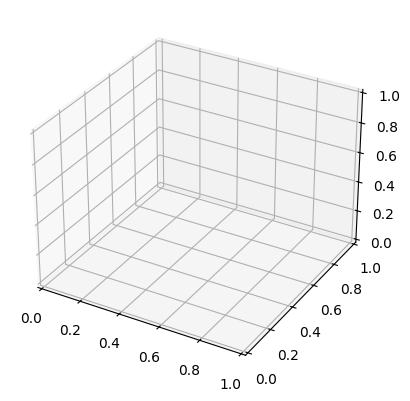

In [6]:
Qz_array = np.linspace(1,100,20)
Qdz_array = np.linspace(1,10000,30)
Parameter_array = np.empty((len(Qz_array),len(Qdz_array),2))
for i in range(len(Qz_array)):
    for j in range(len(Qdz_array)):
        Parameter_array[i][j] = (Qz_array[i],Qdz_array[j])
Cost_array = np.empty(Parameter_array.shape[:2])
for i in range(Parameter_array.shape[0]):
    for j in range(Parameter_array.shape[1]):
        (Qz,Qdz) = Parameter_array[i][j]
        Cost_array[i,j] = Cost(4,Qz,4,Qdz,131,8.2,200,1500)

X, Y = np.meshgrid(Qz_array, Qdz_array, indexing="ij")   # same shape as Cost_array

fig = plt.figure()
ax = fig.add_subplot(projection="3d")
surf = ax.plot_surface(X, Y, -Cost, cmap="viridis")

ax.set_xlabel("Qz")
ax.set_ylabel("Qdz")
ax.set_zlabel("Neg Cost")
fig.colorbar(surf, shrink=0.6, label="Neg Cost")
plt.show()

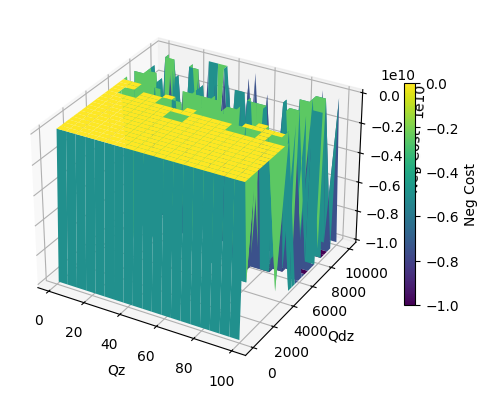

In [7]:
X, Y = np.meshgrid(Qz_array, Qdz_array, indexing="ij")   # same shape as Cost_array

fig = plt.figure()
ax = fig.add_subplot(projection="3d")
surf = ax.plot_surface(X, Y, -Cost_array, cmap="viridis")

ax.set_xlabel("Qz")
ax.set_ylabel("Qdz")
ax.set_zlabel("Neg Cost")
fig.colorbar(surf, shrink=0.6, label="Neg Cost")
plt.show()